# 📘 Day 5 (07/11) — Valutazione Avanzata: PPL, Benchmark e Valutazione Umana

**Obiettivo pratico (4 ore di codice)**: Implementare metriche avanzate (perplessità), usare lm-eval-harness per benchmark, valutare su SQuAD, e condurre valutazione umana in classe.

---

## 🗺️ Roadmap della lezione (240 minuti di codice)

| **Sezione** | **Contenuto** | **Tempo stimato** |
|-------------|---------------|-------------------|
| 1 | Setup e teoria metriche tradizionali | 20' |
| 2 | Calcolo perplessità (PPL) | 50' |
| 3 | lm-eval-harness per benchmark | 60' |
| 4 | Valutazione su SQuAD (QA) | 60' |
| 5 | Valutazione umana in classe | 40' |
| 6 | Report finale e best practices | 10' |
| **TOTALE** | | **240'** |

---

## 📚 Leggi dopo (teoria fuori orario)

### Perplessità (Perplexity, PPL)
- **Definizione**: misura quanto il modello è "sorpreso" da una sequenza
- **Formula**: `PPL = exp(- (1/N) Σ log P(w_i | context))`
- **Interpretazione**: PPL bassa = modello prevede bene il testo
- **Range**: [1, +∞), tipicamente 10-100 per LLM moderni
- **Uso**: valutare qualità modello linguistico
- **Limiti**: non cattura utilità o allineamento

### Benchmark generali
- **lm-evaluation-harness**: framework per valutare LLM su task standard
- **Open LLM Leaderboard**: classifica pubblica su Hugging Face
- **HELM** (Stanford): benchmark olistico con 42 scenari
- **MMLU**: 57 task multi-disciplinari

### Benchmark task-specific
- **SQuAD**: Question Answering su Wikipedia
- **CNN/DailyMail**: Summarization di articoli
- **WMT**: Traduzione automatica
- **GLUE/SuperGLUE**: comprensione linguaggio naturale

### Valutazione umana
- **Criteri**: qualità, utilità, sicurezza, coerenza
- **Rubric**: scala Likert (1-5) per ogni criterio
- **Inter-annotator agreement**: Cohen's kappa, Fleiss' kappa
- **Costi**: $1-10 per valutazione
- **Best practices**: annotatori multipli, training, calibrazione

---

## 1️⃣ Setup e teoria metriche tradizionali (20 minuti)

In [7]:
# Installazione librerie
%pip install torch transformers datasets lm-eval matplotlib pandas numpy scikit-learn -q

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Import librerie

# Importa PyTorch, utilizzato per eseguire il modello
# e lavorare con i tensori
import torch

# Importa gli strumenti Hugging Face per caricare:
# - il tokenizer;
# - il modello causale;
# - il seed per rendere gli esperimenti riproducibili.
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed

# Importa la funzione per caricare dataset da Hugging Face.
from datasets import load_dataset

# Importa Matplotlib per creare grafici.
import matplotlib.pyplot as plt

# Importa Pandas per lavorare con tabelle e DataFrame.
import pandas as pd

# Importa NumPy per operazioni numeriche e statistiche.
import numpy as np

# Importa la funzione per calcolare il Cohen's Kappa,
# una misura dell'accordo tra annotatori.
from sklearn.metrics import cohen_kappa_score

# Importa os per gestire cartelle, file e variabili d'ambiente.
import os

# Importa math per eventuali operazioni matematiche aggiuntive.
import math

# Importa warnings per gestire i messaggi di avviso.
import warnings

# Nasconde gli avvisi non essenziali per rendere più pulito l'output.
warnings.filterwarnings('ignore')

# Seed

# Imposta un valore fisso per il seed.
# In questo modo i risultati casuali sono più facilmente riproducibili.
SEED = 42

# Applica il seed alle funzioni casuali utilizzate da Transformers.
set_seed(SEED)

# Device

# Seleziona il dispositivo su cui eseguire il modello:
# GPU CUDA se disponibile, altrimenti CPU.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Mostra la versione di PyTorch installata
print(f"✅ PyTorch: {torch.__version__}")

# Mostra il dispositivo selezionato.
print(f"✅ Device: {device}")

# Mostra il valore del seed utilizzato.
print(f"✅ Seed: {SEED}")

✅ PyTorch: 2.14.0+cpu
✅ Device: cpu
✅ Seed: 42


In [ ]:
# Creazione directory
# Crea la cartella in cui verranno salvati i risultati degli esperimenti.

os.makedirs(
    './results_day5',        # Percorso della cartella da creare
    exist_ok=True            # Non genera errore se la cartella esiste già
)

# Conferma che la cartella è pronta per essere utilizzata.
print("✅ Directory create")

✅ Directory create


### 📖 Panoramica metriche tradizionali

| **Metrica** | **Cosa misura** | **Range** | **Uso principale** | **Vantaggi** | **Limiti** |
|-------------|-----------------|-----------|-------------------|--------------|------------|
| **Perplessità** | Sorpresa del modello | [1, +∞) | Language modeling | Veloce, interpretabile | Non cattura utilità |
| **BLEU** | Precision n-grammi | [0, 1] | Traduzione | Standard, veloce | Favorisce match esatti |
| **ROUGE** | Recall n-grammi | [0, 1] | Summarization | Complementare a BLEU | Ignora semantica |
| **Accuracy** | Predizioni corrette | [0, 1] | Classification | Semplice | Misleading con classi sbilanciate |
| **F1** | Media armonica P/R | [0, 1] | Classification | Bilancia precision/recall | Non adatto a multi-class |

### Quando usare quale metrica:
- **Language modeling**: Perplessità
- **Traduzione**: BLEU, METEOR
- **Summarization**: ROUGE, BERTScore
- **QA**: Exact Match (EM), F1
- **Classification**: Accuracy, F1, AUC-ROC
- **Generazione aperta**: Valutazione umana + metriche automatiche

---

## 2️⃣ Calcolo perplessità (PPL) (50 minuti)

La **perplessità** misura quanto il modello è "sorpreso" da una sequenza di token.

**Formula**:
```
PPL = exp(- (1/N) Σ log P(w_i | w_1, ..., w_{i-1}))
```

**Interpretazione**:
- PPL = 1: modello perfetto (predice sempre correttamente)
- PPL = 10: in media, modello è incerto tra 10 token
- PPL = 100: in media, modello è incerto tra 100 token

**Valori tipici**:
- GPT-2: PPL ~20-30 su test set
- GPT-3: PPL ~15-20
- Modelli piccoli: PPL ~50-100

In [ ]:
# Carica modello


# Specifica il nome del modello pre-addestrato da utilizzare.
# distilgpt2 è una versione più compatta e veloce di GPT-2.
MODEL_NAME = 'distilgpt2'

# Mostra un messaggio per informare l'utente
# che il caricamento del modello è iniziato.
print(f"⏳ Caricamento {MODEL_NAME}...")

# Carica il tokenizer associato al modello.
# Il tokenizer converte il testo in token numerici
# che il modello è in grado di elaborare.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Carica l'architettura e i pesi del modello pre-addestrato.
# AutoModelForCausalLM indica un modello causale,
# cioè un modello che predice il token successivo.
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)

# Imposta il modello in modalità valutazione.
# In questa modalità vengono disattivate alcune operazioni
# utilizzate esclusivamente durante l'addestramento, come il dropout.
model.eval()

# Sposta il modello sul dispositivo disponibile:
# GPU se CUDA è disponibile, altrimenti CPU.
model.to(device)

# Conferma che il modello è stato caricato correttamente
# e mostra il dispositivo utilizzato.
print(f"✅ Modello caricato su {device}")

⏳ Caricamento distilgpt2...


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

✅ Modello caricato su cpu


In [ ]:
# Funzione per calcolare perplessità
def calculate_perplexity(model, tokenizer, text: str) -> float:
    """
    Calcola perplessità di un testo.
    
    Args:
        model: modello causal LM
        tokenizer: tokenizer
        text: testo da valutare
    
    Returns:
        Perplessità (float)
    """
    # Tokenizza
    # Converte il testo in token numerici comprensibili dal modello.
    # return_tensors='pt' restituisce i token sotto forma di tensori PyTorch.
    encodings = tokenizer(text, return_tensors='pt')

    # Sposta i token sullo stesso dispositivo del modello, CPU o GPU.
    input_ids = encodings.input_ids.to(device)
    
    # Calcola loss
    # Calcola la loss senza memorizzare i gradienti,
    # perché stiamo valutando il modello e non lo stiamo addestrando.
    with torch.no_grad():
        # Passando labels=input_ids, il modello confronta ogni token
        # con il token atteso e calcola la loss media.
        outputs = model(input_ids, labels=input_ids)

        # Estrae il valore numerico della loss calcolata.
        loss = outputs.loss
    
    # Perplessità = exp(loss)
    # La perplessità è l'esponenziale della loss:
    # PPL = exp(loss)
    # Una perplessità più bassa indica che il modello prevedeva meglio il testo.
    perplexity = torch.exp(loss).item()

    # Restituisce la perplessità come valore float.
    return perplexity

# Test
# Definisce alcuni testi di esempio da valutare.
test_texts = [
    "The quick brown fox jumps over the lazy dog.",
    "Machine learning is a subset of artificial intelligence.",
    "asdfjkl qwerty zxcvbn"  # Testo nonsense
]

# Mostra un messaggio prima di iniziare i test.
print("\n🧪 Test perplessità:\n")

# Calcola e stampa la perplessità di ogni testo.
for text in test_texts:
    # Applica la funzione al testo corrente.
    ppl = calculate_perplexity(model, tokenizer, text)

    # Stampa il testo analizzato.
    print(f"Text: {text}")

    # Stampa la perplessità arrotondata a due cifre decimali.
    print(f"PPL: {ppl:.2f}\n")


🧪 Test perplessità:

Text: The quick brown fox jumps over the lazy dog.
PPL: 569.89

Text: Machine learning is a subset of artificial intelligence.
PPL: 65.65

Text: asdfjkl qwerty zxcvbn
PPL: 497.89



In [ ]:
# Calcola perplessità su dataset
# Usiamo WikiText-2 (dataset standard per language modeling)

# Carica la versione di test del dataset WikiText-2.
# 'Salesforce/wikitext' identifica il dataset su Hugging Face.
# 'wikitext-2-raw-v1' specifica la configurazione del dataset.
# split='test' seleziona soltanto la parte destinata alla valutazione.
print("⏳ Caricamento WikiText-2...")

dataset = load_dataset(
    'Salesforce/wikitext',      # Nome del dataset online
    'wikitext-2-raw-v1',        # Configurazione: versione non preprocessata del dataset
    split='test'                # Seleziona il sottoinsieme di test per la valutazione
)

# Usa subset per velocità
# Seleziona soltanto i testi con più di 50 caratteri.
# Usiamo un massimo di 50 testi per ridurre il tempo di calcolo.
texts = [ex['text'] for ex in dataset if len(ex['text']) > 50][:50]

print(f"✅ {len(texts)} testi caricati")

⏳ Caricamento WikiText-2...


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

✅ 50 testi caricati


In [ ]:
# Calcola perplessità per ogni testo
print("\n⏳ Calcolo perplessità su WikiText-2... (questo richiederà qualche minuto)\n")

# Lista in cui verranno salvati i valori di perplessità
# calcolati per i singoli testi.
perplexities = []

# Scorre tutti i testi e tiene traccia dell'indice corrente.
for i, text in enumerate(texts):

    # Ogni 10 testi mostra lo stato di avanzamento del calcolo.
    if i % 10 == 0:
        print(f"Progresso: {i}/{len(texts)}")
    
    try:
        # Calcola la perplessità del testo corrente
        # usando il modello e il tokenizer caricati in precedenza.
        ppl = calculate_perplexity(model, tokenizer, text)

        # Aggiunge il risultato alla lista delle perplessità.
        perplexities.append(ppl)
    except:
        # Se si verifica un errore durante l'elaborazione,
        # ignora il testo problematico e continua con il successivo.
        # Skip testi problematici
        continue

# Calcola la perplessità media di tutti i testi elaborati.
mean_ppl = np.mean(perplexities)

# Calcola la perplessità centrale della distribuzione.
# La mediana è meno influenzata da valori estremamente alti o bassi.
median_ppl = np.median(perplexities)

# Calcola la deviazione standard, che indica quanto
# i valori si discostano mediamente dalla media.
std_ppl = np.std(perplexities)

# Mostra il numero di testi elaborati correttamente.
print(f"\n✅ Perplessità calcolata su {len(perplexities)} testi")

# Stampa le principali statistiche calcolate.
print(f"\n📊 Statistiche:")

# Mostra la perplessità media con due cifre decimali.
print(f"   Media: {mean_ppl:.2f}")

# Mostra la mediana dei valori di perplessità.
print(f"   Mediana: {median_ppl:.2f}")

# Mostra la deviazione standard.
print(f"   Std Dev: {std_ppl:.2f}")

# Mostra il valore minimo osservato.
print(f"   Min: {np.min(perplexities):.2f}")

# Mostra il valore massimo osservato.
print(f"   Max: {np.max(perplexities):.2f}")


⏳ Calcolo perplessità su WikiText-2... (questo richiederà qualche minuto)

Progresso: 0/50
Progresso: 10/50
Progresso: 20/50
Progresso: 30/50
Progresso: 40/50

✅ Perplessità calcolata su 50 testi

📊 Statistiche:
   Media: 109.89
   Mediana: 78.88
   Std Dev: 81.83
   Min: 37.04
   Max: 557.55



✅ Grafico salvato in ./results_day5/perplexity_distribution.png


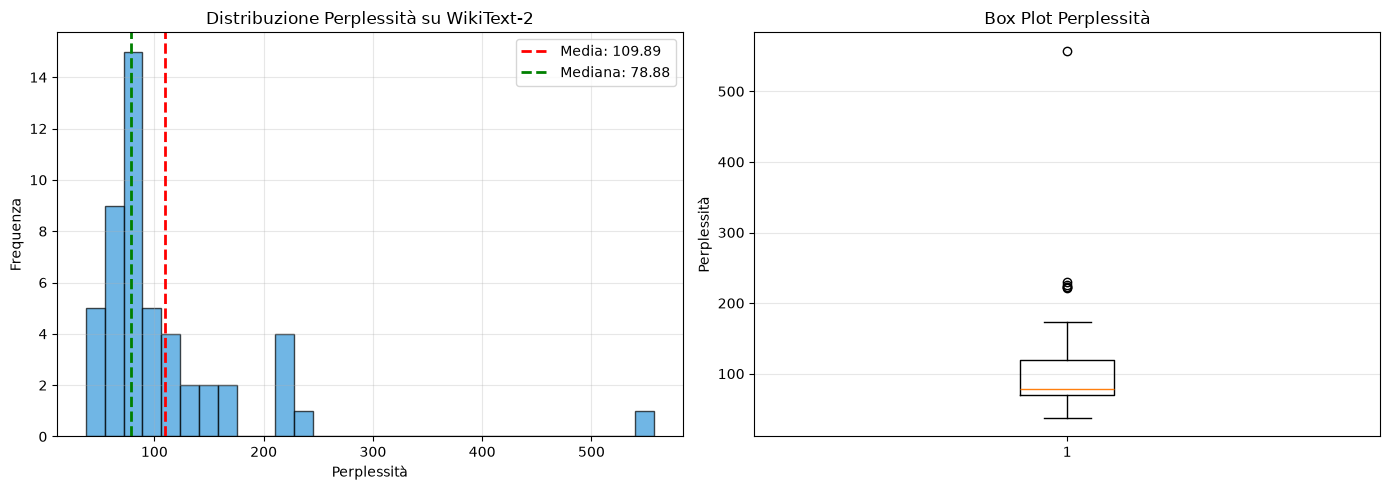

In [16]:
# Visualizza distribuzione perplessità

# Crea una figura con due grafici affiancati:
# il primo per l'istogramma e il secondo per il box plot.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -------------------------
# Grafico 1: Istogramma
# -------------------------
# Plot 1: Histogram

# Mostra quante volte compaiono i diversi intervalli di perplessità.
# bins=30 divide i valori in 30 intervalli.
axes[0].hist(
    perplexities, 
    bins=30, 
    color='#3498db', 
    alpha=0.7, 
    edgecolor='black'
)

# Disegna una linea verticale rossa in corrispondenza della media.
axes[0].axvline(
    mean_ppl, 
    color='red', 
    linestyle='--', 
    linewidth=2, 
    label=f'Media: {mean_ppl:.2f}'
)

# Disegna una linea verticale verde in corrispondenza della mediana.
axes[0].axvline(
    median_ppl, 
    color='green', 
    linestyle='--', 
    linewidth=2, 
    label=f'Mediana: {median_ppl:.2f}'
)

# Imposta l'etichetta dell'asse orizzontale.
axes[0].set_xlabel('Perplessità')

# Imposta l'etichetta dell'asse verticale.
axes[0].set_ylabel('Frequenza')

# Imposta il titolo dell'istogramma.
axes[0].set_title('Distribuzione Perplessità su WikiText-2')

# Mostra la legenda con media e mediana.
axes[0].legend()

# Aggiunge una griglia per facilitare la lettura del grafico.
axes[0].grid(True, alpha=0.3)

# -------------------------
# Grafico 2: Box plot
# -------------------------
# Plot 2: Box plot

# Crea un box plot per mostrare:
# mediana, quartili, dispersione e possibili valori anomali.
axes[1].boxplot(perplexities, vert=True)

# Imposta l'etichetta dell'asse verticale.
axes[1].set_ylabel('Perplessità')

# Imposta il titolo del box plot.
axes[1].set_title('Box Plot Perplessità')

# Aggiunge una griglia orizzontale per facilitare il confronto dei valori.
axes[1].grid(True, alpha=0.3, axis='y')

# Riduce automaticamente gli spazi vuoti tra i grafici.
plt.tight_layout()

# Salva il grafico come immagine PNG.
# dpi=150 definisce la qualità dell'immagine.
# bbox_inches='tight' evita di tagliare titoli ed etichette.
plt.savefig('./results_day5/perplexity_distribution.png', 
            dpi=150,    # imposta la risoluzione dell'immagine 
            bbox_inches='tight' # riduce automaticamente i margini vuoti e impedisce che titoli, 
                                # etichette o legenda vengano tagliati
)

# Conferma che il file è stato salvato correttamente.
print("\n✅ Grafico salvato in ./results_day5/perplexity_distribution.png")

# Mostra i grafici nel notebook.
plt.show()

### 💡 Interpretazione:

**Perplessità bassa** (< 30):
- Modello predice bene il testo
- Testo probabilmente in-distribution (simile a training data)

**Perplessità media** (30-100):
- Modello ha incertezza moderata
- Testo potrebbe essere out-of-distribution

**Perplessità alta** (> 100):
- Modello molto incerto
- Testo probabilmente molto diverso da training data
- Possibile testo nonsense o linguaggio tecnico

**Limiti**:
- Non misura utilità o allineamento
- Può essere bassa anche per testo inutile
- Dipende fortemente da training data

---

## 3️⃣ lm-eval-harness per benchmark (60 minuti)

**lm-evaluation-harness** è un framework di EleutherAI per valutare LLM su task standard.

**Task supportati**: 200+
- **MMLU**: 57 task multi-disciplinari
- **HellaSwag**: common sense reasoning
- **TruthfulQA**: truthfulness
- **GSM8K**: math reasoning
- **HumanEval**: code generation

**Output**: accuracy, perplexity, F1, etc.

In [17]:
# Installazione lm-eval
%pip install lm-eval -q

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Importa il modulo per eseguire comandi esterni, come lm-eval.
import subprocess

# Importa il modulo per leggere i risultati in formato JSON.
import json

# Importa il modulo per gestire variabili d'ambiente e percorsi.
import os

# Importa il modulo per cercare file usando pattern,
# ad esempio tutti i file JSON presenti in una cartella.
import glob

# Mostra un messaggio per informare l'utente dell'inizio del benchmark.
print("⏳ Esecuzione lm-eval su task semplice (hellaswag)...")

# Avvisa che l'esecuzione potrebbe richiedere diversi minuti.
print("   Nota: questo richiederà ~5-10 minuti\n")

# Imposta variabile ambiente per UTF-8 (Windows)
# Crea una copia delle variabili d'ambiente del sistema.
env = os.environ.copy()
env['PYTHONIOENCODING'] = 'utf-8'

# Esegui lm-eval
# Costruisce il comando da eseguire tramite lm-eval
cmd = [
    'lm_eval',                                      # Comando del framework lm-evaluation-harness
    '--device', 'cpu',                              # Esegue il benchmark sulla CPU
    '--model', 'hf',                                # Usa un modello Hugging Face
    '--model_args', f'pretrained={MODEL_NAME}',     # Specifica il modello da valutare
    '--tasks', 'hellaswag',                         # Seleziona il benchmark HellaSwag
    '--limit', '10',                                # Usa solo 10 esempi per velocizzare il test
    '--output_path', './results_day5/lm_eval_results'   # Cartella dei risultati
]

try:
    # Esegui con encoding UTF-8
    # Esegue il comando lm-eval creato sopra
    result = subprocess.run(
        cmd,                    
        capture_output=True,    # Salva l'output prodotto dal comando
        text=True,              # Restituisce l'output come stringa
        encoding='utf-8',       # Forza UTF-8
        errors='replace',       # Sostituisci caratteri non decodificabili
        timeout=900,            # Interrompe il processo dopo 900 secondi
        env=env                 # Usa le variabili d'ambiente configurate
    )
    
    # Stampa output (può contenere Unicode)
    # Se lm-eval ha prodotto un output, lo stampa nel notebook.
    if result.stdout:
        print(result.stdout)

    # Controlla se il comando è terminato con un codice diverso da zero.
    # Un codice diverso da zero generalmente indica un errore.
    if result.returncode != 0:
        print(f"\n⚠️  lm-eval exit code: {result.returncode}")

        # Se è presente un messaggio di errore, stampa i primi 500 caratteri.
        if result.stderr:
            print(f"stderr: {result.stderr[:500]}...")  # Primi 500 char
    
    # Leggi risultati da JSON
    # Cerca file JSON nella directory results_day5/lm_eval_results/distilgpt2/
    # Cerca i file JSON generati durante l'esecuzione di lm-eval.
    json_files = glob.glob('./results_day5/lm_eval_results/distilgpt2/*.json')

    # Controlla se è stato trovato almeno un file JSON.
    if json_files:

        # Se ci sono più file, seleziona il primo trovato.
        json_path = json_files[0]  # Prendi il primo

        # Mostra il percorso del file dei risultati.
        print(f"\n📊 Lettura risultati da: {json_path}")

    # Apre il file JSON in modalità lettura.
    with open(json_path, 'r', encoding='utf-8') as f:
        # Legge il contenuto del file JSON aperto tramite `f`
        # e lo converte in un oggetto Python, generalmente un dizionario.
        results = json.load(f)
    try:

        # Apre il file JSON in modalità lettura.
        with open(json_path, 'r', encoding='utf-8') as f:
            # Legge il contenuto del file JSON aperto tramite `f`
            # e lo converte in un oggetto Python, generalmente un dizionario.   
            results = json.load(f)

        # Mostra un'intestazione per i risultati del benchmark.
        print("\n✅ Risultati lm-eval (hellaswag):\n")

        # Controlla che il JSON contenga la chiave 'results'.
        if 'results' in results:

            # Scorre ogni task e le relative metriche.
            for task, metrics in results['results'].items():
                # stampa ogni task
                print(f"   Task: {task}")

                # Stampa tutte le metriche disponibili per il task.
                for metric, value in metrics.items():

                    # Formatta i valori numerici con quattro cifre decimali.
                    if isinstance(value, (int, float)):
                        print(f"      {metric}: {value:.4f}")

                    # Stampa gli altri valori senza formattazione numerica.
                    else:
                        print(f"      {metric}: {value}")

        # Comunica dove sono stati salvati i risultati completi.
        print(f"\n💡 Risultati completi salvati in: {json_path}")

    # Gestisce il caso in cui il file venga eliminato o non sia accessibile.    
    except FileNotFoundError:
        print(f"\n⚠️  File risultati non trovato: {json_path}")
        print("   lm-eval potrebbe non aver completato correttamente")

    # Gestisce eventuali altri errori durante la lettura del JSON.    
    except Exception as e:
        print(f"\n⚠️  Errore lettura JSON: {e}")

# Gestisce il superamento del tempo massimo di 15 minuti.
except subprocess.TimeoutExpired:
    print("\n⚠️ lm-eval timeout (>15 minuti)")

# Gestisce il caso in cui il comando lm_eval non sia installato.
except FileNotFoundError:
    print("\n⚠️ lm_eval non installato")
    print("   Installa con: pip install lm-eval")

# Gestisce eventuali errori imprevisti durante l'esecuzione.
except Exception as e:
    print(f"\n⚠️ Errore: {e}")


⏳ Esecuzione lm-eval su task semplice (hellaswag)...
   Nota: questo richiederà ~5-10 minuti

hf ({'pretrained': 'distilgpt2'}), gen_kwargs: ({}), limit: 10.0, num_fewshot: None, batch_size: 1
|  Tasks  |Version|Filter|n-shot| Metric |   |Value|   |Stderr|
|---------|------:|------|-----:|--------|---|----:|---|-----:|
|hellaswag|      1|none  |     0|acc     |↑  |  0.3|±  |0.1528|
|         |       |none  |     0|acc_norm|↑  |  0.4|±  |0.1633|



📊 Lettura risultati da: ./results_day5/lm_eval_results/distilgpt2\results_2026-09-25T14-44-26.078849.json

✅ Risultati lm-eval (hellaswag):

   Task: hellaswag
      name: hellaswag
      alias: hellaswag
      sample_len: 10.0000
      acc,none: 0.3000
      acc_stderr,none: 0.1528
      acc_norm,none: 0.4000
      acc_norm_stderr,none: 0.1633

💡 Risultati completi salvati in: ./results_day5/lm_eval_results/distilgpt2\results_2026-09-25T14-44-26.078849.json


### 



💡 Interpretazione risultati lm-eval:

**HellaSwag** (common sense reasoning):
- **Accuracy**: % risposte corrette
- **Baseline random**: 25% (4 opzioni)
- **GPT-2 small**: ~30-35%
- **GPT-3**: ~80%
- **Umani**: ~95%

**Come usare lm-eval in produzione**:
1. Scegli task rilevanti per il tuo use case
2. Esegui su modello base e fine-tuned
3. Confronta risultati
4. Monitora nel tempo per regression

**Esempio: Open LLM Leaderboard**
- Usa 6 task: ARC, HellaSwag, MMLU, TruthfulQA, Winogrande, GSM8K
- Classifica pubblica su Hugging Face
- Aggiornata settimanalmente

---

## 4️⃣ Valutazione su SQuAD (QA) (60 minuti)

**SQuAD** (Stanford Question Answering Dataset) è un benchmark per QA estrattivo.

**Formato**:
- **Context**: paragrafo di Wikipedia
- **Question**: domanda sul context
- **Answer**: span di testo nel context

**Metriche**:
- **Exact Match (EM)**: % risposte esattamente corrette
- **F1**: overlap token tra predizione e gold answer

In [ ]:
# Carica SQuAD
print("⏳ Caricamento SQuAD...")

squad = load_dataset('squad', split='validation')

# Usa subset
squad_subset = squad.select(range(50))

print(f"✅ {len(squad_subset)} esempi caricati")
print(f"\n📊 Esempio:\n")
example = squad_subset[0]
print(f"Context: {example['context'][:200]}...")
print(f"\nQuestion: {example['question']}")
print(f"\nAnswer: {example['answers']['text'][0]}")

⏳ Caricamento SQuAD...
✅ 50 esempi caricati

📊 Esempio:

Context: Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion Denver Broncos defeated...

Question: Which NFL team represented the AFC at Super Bowl 50?

Answer: Denver Broncos


In [ ]:
# Funzione per generare risposta QA
def generate_qa_answer(model, tokenizer, context: str, question: str, max_new_tokens: int = 20) -> str:
    """
    Genera risposta a domanda dato contesto.
    
    Nota: questo è un approccio generativo semplificato.
    Per QA estrattivo vero, serve modello specifico (es. BERT for QA).
    
    Args:
        model: modello generativo
        tokenizer: tokenizer
        context: contesto
        question: domanda
        max_new_tokens: max token da generare
    
    Returns:
        Risposta generata
    """
    # Formato prompt
    prompt = f"Context: {context}\n\nQuestion: {question}\n\nAnswer:"
    
    inputs = tokenizer(prompt, return_tensors='pt', truncation=True, max_length=512)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,  # Greedy decoding per determinismo
            pad_token_id=tokenizer.eos_token_id
        )
    
    # Decodifica
    full_output = tokenizer.decode(outputs[0], skip_special_tokens=True)
    
    # Estrai solo la risposta (dopo "Answer:")
    if "Answer:" in full_output:
        answer = full_output.split("Answer:")[-1].strip()
    else:
        answer = full_output
    
    return answer

# Test
test_answer = generate_qa_answer(
    model, 
    tokenizer, 
    example['context'], 
    example['question']
)

print(f"\n🧪 Test QA:\n")
print(f"Question: {example['question']}")
print(f"Gold answer: {example['answers']['text'][0]}")
print(f"Generated answer: {test_answer}")


🧪 Test QA:

Question: Which NFL team represented the AFC at Super Bowl 50?
Gold answer: Denver Broncos
Generated answer: The AFC was the first NFL team to win Super Bowl 50. The AFC was the first NFL team


In [ ]:
# Metriche QA

# Metriche per valutare le risposte di un sistema di Question Answering.

def calculate_em(gold: str, pred: str) -> int:
    """
    Calcola Exact Match.
    
    Args:
        gold: risposta gold
        pred: risposta predetta
    
    Returns:
        1 se match esatto, 0 altrimenti
    """
    # Confronta le due stringhe.
    # bool viene convertito in intero:
    # True diventa 1, False diventa 0.
    return int(gold.lower().strip() == pred.lower().strip())

def calculate_f1(gold: str, pred: str) -> float:
    """
    Calcola F1 score basato su overlap token.
    
    Args:
        gold: risposta gold
        pred: risposta predetta
    
    Returns:
        F1 score (0-1)
    """

    # Divide le risposte in parole dopo averle normalizzate.
    # set elimina eventuali parole duplicate.
    gold_tokens = set(gold.lower().split())
    pred_tokens = set(pred.lower().split())

    # Se una delle due risposte è vuota,
    # non è possibile calcolare una sovrapposizione.
    if len(gold_tokens) == 0 or len(pred_tokens) == 0:
        return 0.0

    # Trova le parole presenti sia nella risposta corretta
    # sia nella risposta predetta.
    common = gold_tokens & pred_tokens

    # Se non ci sono parole in comune, il punteggio è zero.
    if len(common) == 0:
        return 0.0

    # Precisione: quante parole predette sono corrette?
    precision = len(common) / len(pred_tokens)

    # Recall: quante parole della risposta corretta sono state trovate?
    recall = len(common) / len(gold_tokens)

    # Calcola la media armonica tra precisione e recall.
    # La media armonica penalizza i casi in cui uno dei due valori è basso.
    f1 = 2 * (precision * recall) / (precision + recall)

    # Restituisce il punteggio F1.
    return f1

# Test metriche

# Test delle metriche con tre casi diversi.
print("\n🧪 Test metriche QA:\n")

# Risposta corretta di riferimento.
gold = "The quick brown fox"

# Risposta identica alla risposta corretta.
pred1 = "The quick brown fox"  # Identico

# Risposta parzialmente corretta.
pred2 = "The brown fox"  # Parziale

# Risposta completamente diversa.
pred3 = "A lazy dog"  # Diverso

# Stampa la risposta corretta
print(f"Gold: {gold}")

# Valuta il primo caso.
print(f"\nPred1 (identico): {pred1}")
print(f"   EM: {calculate_em(gold, pred1)}, F1: {calculate_f1(gold, pred1):.4f}")

# Valuta il secondo caso.
print(f"\nPred2 (parziale): {pred2}")
print(f"   EM: {calculate_em(gold, pred2)}, F1: {calculate_f1(gold, pred2):.4f}")

# Valuta il terzo caso.
print(f"\nPred3 (diverso): {pred3}")
print(f"   EM: {calculate_em(gold, pred3)}, F1: {calculate_f1(gold, pred3):.4f}")


🧪 Test metriche QA:

Gold: The quick brown fox

Pred1 (identico): The quick brown fox
   EM: 1, F1: 1.0000

Pred2 (parziale): The brown fox
   EM: 0, F1: 0.8571

Pred3 (diverso): A lazy dog
   EM: 0, F1: 0.0000


In [ ]:
# Valuta su SQuAD subset
# Valuta il modello su un sottoinsieme del dataset SQuAD.
print("\n⏳ Valutazione su SQuAD... (questo richiederà ~10-15 minuti)\n")

# Liste che conterranno i punteggi EM e F1
# calcolati per ogni esempio valido.
em_scores = []
f1_scores = []

# Scorre tutti gli esempi presenti nel sottoinsieme SQuAD.
for i, example in enumerate(squad_subset):

    # Mostra il progresso ogni 10 esempi elaborati.
    if i % 10 == 0:
        print(f"Progresso: {i}/{len(squad_subset)}")
    
    try:
        # Genera risposta
        # Genera una risposta usando:
        # - il contesto dell'esempio;
        # - la domanda associata al contesto;
        # - il modello e il tokenizer caricati in precedenza.
        pred_answer = generate_qa_answer(
            model,
            tokenizer,
            example['context'],
            example['question']
        )
        
        # Gold answer (prendi prima risposta se multiple)
        # Recupera la risposta corretta di riferimento.
        # Se sono presenti più risposte valide, usa la prima.
        gold_answer = example['answers']['text'][0]
        
        # Calcola metriche

        # Calcola l'Exact Match:
        # vale 1 se la risposta predetta coincide con quella corretta,
        # altrimenti vale 0.
        em = calculate_em(gold_answer, pred_answer)

        # Calcola il punteggio F1 basato sulle parole condivise
        # tra risposta corretta e risposta generata.
        f1 = calculate_f1(gold_answer, pred_answer)

        # Salva i punteggi ottenuti nelle rispettive liste.
        em_scores.append(em)
        f1_scores.append(f1)
    except:
        # Skip esempi problematici
        # Se un esempio causa un errore, lo ignora
        # e continua la valutazione sugli esempi successivi.
        continue

# Calcola la media dei punteggi EM e la converte in percentuale.
mean_em = np.mean(em_scores) * 100  # Converti in percentuale

# Calcola la media dei punteggi F1 e la converte in percentuale.
mean_f1 = np.mean(f1_scores) * 100

# Mostra quanti esempi sono stati valutati correttamente.
print(f"\n✅ Valutazione completata su {len(em_scores)} esempi")

# Mostra i risultati medi ottenuti dal modello.
print(f"\n📊 Risultati SQuAD:")
print(f"   Exact Match (EM): {mean_em:.2f}%")
print(f"   F1 Score: {mean_f1:.2f}%")

# Confronta i risultati con alcune baseline indicative.
print(f"\n💡 Confronto con baseline:")

# Risultato approssimativo ottenuto da un sistema casuale.
print(f"   Random: EM ~0%, F1 ~10%")

# Risultati indicativi di un modello BERT addestrato per il QA estrattivo.
print(f"   BERT-base: EM ~80%, F1 ~88%")

# Risultati indicativi ottenuti da valutatori umani.
print(f"   Umani: EM ~82%, F1 ~91%")


⏳ Valutazione su SQuAD... (questo richiederà ~10-15 minuti)

Progresso: 0/50
Progresso: 10/50
Progresso: 20/50
Progresso: 30/50
Progresso: 40/50

✅ Valutazione completata su 50 esempi

📊 Risultati SQuAD:
   Exact Match (EM): 0.00%
   F1 Score: 6.56%

💡 Confronto con baseline:
   Random: EM ~0%, F1 ~10%
   BERT-base: EM ~80%, F1 ~88%
   Umani: EM ~82%, F1 ~91%



✅ Grafico salvato in ./results_day5/squad_results.png


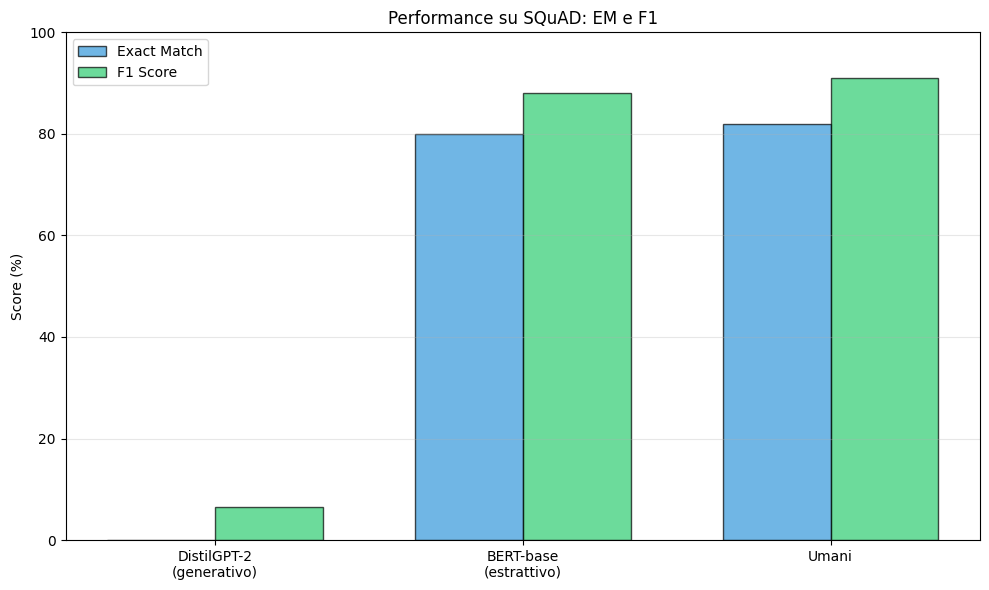

In [ ]:
# Visualizza risultati
fig, ax = plt.subplots(figsize=(10, 6))

models = ['DistilGPT-2\n(generativo)', 'BERT-base\n(estrattivo)', 'Umani']
em_values = [mean_em, 80, 82]
f1_values = [mean_f1, 88, 91]

x = np.arange(len(models))
width = 0.35

ax.bar(x - width/2, em_values, width, label='Exact Match', color='#3498db', alpha=0.7, edgecolor='black')
ax.bar(x + width/2, f1_values, width, label='F1 Score', color='#2ecc71', alpha=0.7, edgecolor='black')

ax.set_ylabel('Score (%)')
ax.set_title('Performance su SQuAD: EM e F1')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, 100)

plt.tight_layout()
plt.savefig('./results_day5/squad_results.png', dpi=150, bbox_inches='tight')
print("\n✅ Grafico salvato in ./results_day5/squad_results.png")
plt.show()

### 💡 Osservazioni:

**DistilGPT-2** (generativo):
- Performance basse su QA estrattivo
- Non trainato per questo task
- Tende a generare testo plausibile ma non estratto dal context

**BERT** (estrattivo):
- Ottimo per QA estrattivo
- Trainato specificamente su SQuAD
- Identifica span esatto nel context

**Lezione**: scegli modello giusto per il task!

---

## 5️⃣ Valutazione umana in classe (40 minuti)

Conduciamo una valutazione umana collaborativa in classe.

### 📋 Protocollo valutazione umana

**Obiettivo**: valutare risposte di 3 modelli (Base, SFT, RLHF) su 5 prompt

**Criteri di valutazione** (scala 1-5):
1. **Cortesia**: tono educato e professionale
2. **Informatività**: fornisce informazioni utili
3. **Risoluzione**: risolve il problema del cliente
4. **Chiarezza**: linguaggio chiaro e comprensibile
5. **Sicurezza**: non fornisce info dannose/false

**Procedura**:
1. Dividi classe in gruppi di 3 studenti
2. Ogni gruppo valuta le stesse 5 risposte
3. Ogni studente valuta indipendentemente
4. Confronta valutazioni e calcola inter-annotator agreement
5. Discuti disaccordi e convergi su valutazione finale

In [ ]:
# Template per valutazione

# Template generale per organizzare le valutazioni umane.
# Le liste vuote verranno eventualmente riempite con i dati
# raccolti durante la valutazione in classe.
evaluation_template = {
    'Prompt': [],
    'Modello': [],
    'Risposta': [],
    'Annotatore': [],
    'Cortesia': [],
    'Informatività': [],
    'Risoluzione': [],
    'Chiarezza': [],
    'Sicurezza': [],
    'Media': []
}

# Esempio di valutazione (simulata)
# In classe, gli studenti compilerebbero questo manualmente

# Esempio di valutazioni simulate.
# In una vera attività in classe, questi dati verrebbero
# compilati manualmente dagli studenti.
example_evaluations = [

    # Valutazioni dell'annotatore A1.
    # Ogni dizionario rappresenta la valutazione di un modello.

    # Annotatore 1
    {'Prompt': 'How do I track my order?', 'Modello': 'Base', 'Annotatore': 'A1', 'Cortesia': 2, 'Informatività': 2, 'Risoluzione': 1, 'Chiarezza': 3, 'Sicurezza': 3},
    {'Prompt': 'How do I track my order?', 'Modello': 'SFT', 'Annotatore': 'A1', 'Cortesia': 4, 'Informatività': 3, 'Risoluzione': 3, 'Chiarezza': 4, 'Sicurezza': 4},
    {'Prompt': 'How do I track my order?', 'Modello': 'RLHF', 'Annotatore': 'A1', 'Cortesia': 5, 'Informatività': 4, 'Risoluzione': 4, 'Chiarezza': 5, 'Sicurezza': 5},
    
    # Annotatore 2
    {'Prompt': 'How do I track my order?', 'Modello': 'Base', 'Annotatore': 'A2', 'Cortesia': 2, 'Informatività': 1, 'Risoluzione': 1, 'Chiarezza': 2, 'Sicurezza': 3},
    {'Prompt': 'How do I track my order?', 'Modello': 'SFT', 'Annotatore': 'A2', 'Cortesia': 3, 'Informatività': 3, 'Risoluzione': 3, 'Chiarezza': 4, 'Sicurezza': 4},
    {'Prompt': 'How do I track my order?', 'Modello': 'RLHF', 'Annotatore': 'A2', 'Cortesia': 5, 'Informatività': 4, 'Risoluzione': 5, 'Chiarezza': 5, 'Sicurezza': 5},
    
    # Annotatore 3
    {'Prompt': 'How do I track my order?', 'Modello': 'Base', 'Annotatore': 'A3', 'Cortesia': 1, 'Informatività': 2, 'Risoluzione': 2, 'Chiarezza': 3, 'Sicurezza': 3},
    {'Prompt': 'How do I track my order?', 'Modello': 'SFT', 'Annotatore': 'A3', 'Cortesia': 4, 'Informatività': 4, 'Risoluzione': 3, 'Chiarezza': 4, 'Sicurezza': 5},
    {'Prompt': 'How do I track my order?', 'Modello': 'RLHF', 'Annotatore': 'A3', 'Cortesia': 5, 'Informatività': 5, 'Risoluzione': 4, 'Chiarezza': 5, 'Sicurezza': 5},
]

# Converte la lista di dizionari in un DataFrame pandas.
# Ogni dizionario diventa una riga e ogni chiave diventa una colonna.
df_eval = pd.DataFrame(example_evaluations)

# Calcola la media dei cinque criteri per ogni valutazione.
# axis=1 significa che la media viene calcolata riga per riga.
df_eval['Media'] = df_eval[['Cortesia', 'Informatività', 'Risoluzione', 'Chiarezza', 'Sicurezza']].mean(axis=1)

# Stampa la tabella finale delle valutazioni.
# index=False nasconde l'indice numerico del DataFrame.
print("\n📊 Esempio Valutazioni Umane:\n")
print(df_eval.to_string(index=False))


📊 Esempio Valutazioni Umane:

                  Prompt Modello Annotatore  Cortesia  Informatività  Risoluzione  Chiarezza  Sicurezza  Media
How do I track my order?    Base         A1         2              2            1          3          3    2.2
How do I track my order?     SFT         A1         4              3            3          4          4    3.6
How do I track my order?    RLHF         A1         5              4            4          5          5    4.6
How do I track my order?    Base         A2         2              1            1          2          3    1.8
How do I track my order?     SFT         A2         3              3            3          4          4    3.4
How do I track my order?    RLHF         A2         5              4            5          5          5    4.8
How do I track my order?    Base         A3         1              2            2          3          3    2.2
How do I track my order?     SFT         A3         4              4            3

In [ ]:
# Calcola inter-annotator agreement
# Usiamo Cohen's Kappa per coppie di annotatori

# Calcola l'accordo tra gli annotatori usando Cohen's Kappa.
# Cohen's Kappa misura quanto gli annotatori concordano,
# tenendo conto anche dell'accordo casuale.
# Usiamo una versione pesata linearmente perché i punteggi
# sono ordinali e vanno da 1 a 5.

def calculate_agreement(df, criterion):
    """
    Calcola Cohen's Kappa tra tutte le coppie di annotatori.
    """

    # Recupera i nomi degli annotatori senza duplicati.
    annotators = df['Annotatore'].unique()

    # Lista in cui verranno salvati i valori di Kappa.
    kappas = []

    # Scorre ogni annotatore e lo confronta
    # con tutti quelli successivi, evitando confronti duplicati
    for i, ann1 in enumerate(annotators):
        for ann2 in annotators[i+1:]:

            # Seleziona i punteggi assegnati dal primo annotatore
            # per il criterio corrente.
            scores1 = df[df['Annotatore'] == ann1][criterion].values

            # Seleziona i punteggi assegnati dal secondo annotatore.
            scores2 = df[df['Annotatore'] == ann2][criterion].values

            # Procede solo se i due annotatori hanno valutato
            # lo stesso numero di elementi.
            if len(scores1) == len(scores2):

                 # Calcola Cohen's Kappa pesato linearmente.
                # Il peso lineare considera meno grave una differenza
                # di un solo punto rispetto a una differenza maggiore.
                kappa = cohen_kappa_score(
                    scores1, 
                    scores2, 
                    weights='linear'
                )
                # Salva il valore calcolato.
                kappas.append(kappa)

    # Restituisce la media dei valori di Kappa.
    # Se non sono disponibili confronti validi, restituisce 0.0.
    return np.mean(kappas) if kappas else 0.0

# Calcola per ogni criterio
# Elenco dei criteri da analizzare.
criteria = [
    'Cortesia', 
    'Informatività', 
    'Risoluzione', 
    'Chiarezza', 
    'Sicurezza'
]

# Dizionario che conterrà il valore di Kappa per ogni criterio.
agreements = {}

# Calcola l'accordo tra annotatori separatamente
# per ciascun criterio.
for criterion in criteria:

    # Calcola il valore di Cohen's Kappa per il criterio corrente,
    # confrontando le valutazioni dei diversi annotatori.
    kappa = calculate_agreement(df_eval, criterion)

    # Salva il valore calcolato nel dizionario `agreements`,
    # associandolo al nome del criterio analizzato.
    agreements[criterion] = kappa

# Stampa i risultati ottenuti per ogni criterio.
print("\n📊 Inter-Annotator Agreement (Cohen's Kappa):\n")

for criterion, kappa in agreements.items():

    # Mostra Kappa con tre cifre decimali.
    print(f"{criterion}: {kappa:.3f}")

# Calcola la media dei valori di Kappa
# relativi a tutti i criteri.
mean_kappa = np.mean(list(agreements.values()))

# Stampa il valore medio complessivo.
print(f"\nMedia: {mean_kappa:.3f}")

# Mostra una guida per interpretare il valore di Cohen's Kappa.
print("\n💡 Interpretazione Kappa:")
print("   < 0.20: Poor agreement")
print("   0.21-0.40: Fair agreement")
print("   0.41-0.60: Moderate agreement")
print("   0.61-0.80: Substantial agreement")
print("   0.81-1.00: Almost perfect agreement")


📊 Inter-Annotator Agreement (Cohen's Kappa):

Cortesia: 0.707
Informatività: 0.542
Risoluzione: 0.675
Chiarezza: 0.818
Sicurezza: 0.778

Media: 0.704

💡 Interpretazione Kappa:
   < 0.20: Poor agreement
   0.21-0.40: Fair agreement
   0.41-0.60: Moderate agreement
   0.61-0.80: Substantial agreement
   0.81-1.00: Almost perfect agreement



✅ Grafico salvato in ./results_day5/human_evaluation.png


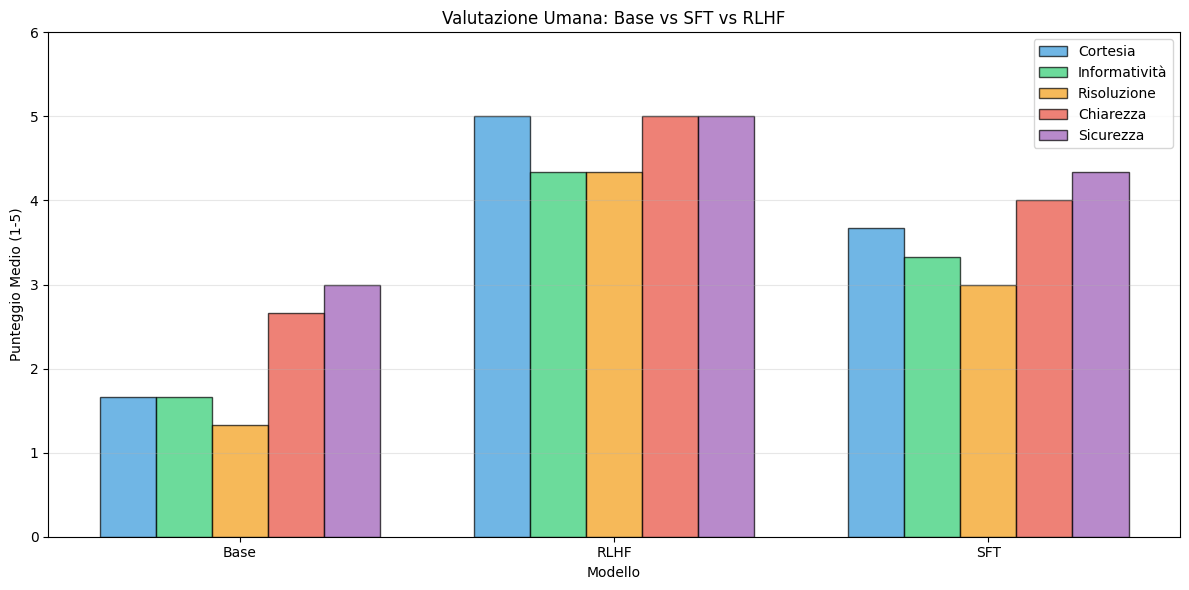

In [ ]:
# Visualizza valutazioni umane
# Calcola media per modello
df_mean = df_eval.groupby('Modello')[criteria].mean()

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(df_mean.index))
width = 0.15

colors = ['#3498db', '#2ecc71', '#f39c12', '#e74c3c', '#9b59b6']

for i, (criterion, color) in enumerate(zip(criteria, colors)):
    offset = width * (i - 2)
    ax.bar(x + offset, df_mean[criterion], width, label=criterion, color=color, alpha=0.7, edgecolor='black')

ax.set_xlabel('Modello')
ax.set_ylabel('Punteggio Medio (1-5)')
ax.set_title('Valutazione Umana: Base vs SFT vs RLHF')
ax.set_xticks(x)
ax.set_xticklabels(df_mean.index)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, 6)

plt.tight_layout()
plt.savefig('./results_day5/human_evaluation.png', dpi=150, bbox_inches='tight')
print("\n✅ Grafico salvato in ./results_day5/human_evaluation.png")
plt.show()

### 💡 Best Practices per valutazione umana:

**Prima della valutazione**:
1. **Training annotatori**: spiega criteri e scala
2. **Calibrazione**: fai valutare 5 esempi insieme e discuti
3. **Blind evaluation**: annotatori non sanno quale modello ha generato cosa

**Durante la valutazione**:
1. **Indipendenza**: annotatori valutano separatamente
2. **Randomizzazione**: ordine casuale di modelli e prompt
3. **Pause**: evita fatigue con pause ogni 10-15 valutazioni

**Dopo la valutazione**:
1. **Calcola agreement**: Cohen's Kappa o Fleiss' Kappa
2. **Risolvi disaccordi**: discussione o annotatore esperto
3. **Analizza pattern**: quali criteri hanno più disaccordo?
4. **Documenta**: salva rubric, istruzioni, e decisioni

---

## 6️⃣ Report finale e best practices (10 minuti)

In [ ]:
# Report finale: riassunto di tutte le metriche
final_report = {
    'Metrica': [
        'Perplessità (WikiText-2)',
        'BLEU (vs reference)',
        'ROUGE-1 (vs reference)',
        'SQuAD EM',
        'SQuAD F1',
        'Valutazione Umana (media)'
    ],
    'Valore': [
        f"{mean_ppl:.2f}",
        "Vedi Day 4",
        "Vedi Day 4",
        f"{mean_em:.2f}%",
        f"{mean_f1:.2f}%",
        f"{df_mean.mean().mean():.2f}/5"  # ✅ Media di tutte le colonne

    ],
    'Interpretazione': [
        'Bassa = migliore',
        'Alta = migliore (0-1)',
        'Alta = migliore (0-1)',
        'Alta = migliore (0-100%)',
        'Alta = migliore (0-100%)',
        'Alta = migliore (1-5)'
    ]
}

df_report = pd.DataFrame(final_report)

print("\n📊 Report Finale Valutazione:\n")
print(df_report.to_string(index=False))

df_report.to_csv('./results_day5/final_report.csv', index=False)
print("\n✅ Report salvato in ./results_day5/final_report.csv")


📊 Report Finale Valutazione:

                  Metrica     Valore          Interpretazione
 Perplessità (WikiText-2)     109.89         Bassa = migliore
      BLEU (vs reference) Vedi Day 4    Alta = migliore (0-1)
   ROUGE-1 (vs reference) Vedi Day 4    Alta = migliore (0-1)
                 SQuAD EM      0.00% Alta = migliore (0-100%)
                 SQuAD F1      6.56% Alta = migliore (0-100%)
Valutazione Umana (media)     3.49/5    Alta = migliore (1-5)

✅ Report salvato in ./results_day5/final_report.csv


### 🎯 Best Practices per Valutazione LLM

**1. Usa approccio multi-metrica**:
- Combina metriche automatiche (velocità) e umane (qualità)
- Nessuna singola metrica è sufficiente

**2. Scegli metriche appropriate per il task**:
- Language modeling: Perplessità
- Traduzione: BLEU, METEOR
- Summarization: ROUGE, BERTScore
- QA: EM, F1
- Generazione aperta: Valutazione umana

**3. Valuta su distribuzione rappresentativa**:
- Test set deve riflettere use case reale
- Include edge cases e failure modes

**4. Monitora nel tempo**:
- Valutazione continua post-deployment
- Regression testing ad ogni update
- A/B testing su utenti reali

**5. Documenta tutto**:
- Dataset, metriche, risultati
- Decisioni e trade-off
- Limiti e failure modes

**6. Considera metriche di business**:
- CSAT (Customer Satisfaction)
- Resolution rate
- Time to resolution
- Cost per interaction

**7. Valuta safety e fairness**:
- Tossicità
- Bias (genere, razza, etc.)
- Allucinazioni
- Privacy leaks

---

## 🎯 Esercizi TODO

### Esercizio 1: Perplessità per categoria
Calcola perplessità separatamente per diverse categorie di testo (news, fiction, code) e confronta.

### Esercizio 2: Benchmark completo
Esegui lm-eval su task multipli (HellaSwag, MMLU, TruthfulQA) e crea leaderboard.

### Esercizio 3: QA con modello specifico
Usa un modello BERT for QA invece di GPT-2 e confronta performance su SQuAD.

### Esercizio 4: Valutazione umana estesa
Conduci valutazione umana su 20 esempi con 5 annotatori e analizza disaccordi.

In [ ]:
# TODO: Esercizio 1 - Perplessità per categoria
# Scrivi qui il tuo codice

In [ ]:
# TODO: Esercizio 2 - Benchmark completo
# Scrivi qui il tuo codice

In [ ]:
# TODO: Esercizio 3 - QA con modello specifico
# Scrivi qui il tuo codice

In [ ]:
# TODO: Esercizio 4 - Valutazione umana estesa
# Scrivi qui il tuo codice

---

## 🎓 Conclusione Day 5 e Corso Completo

### Day 5:
1. ✅ Implementato calcolo **perplessità** su WikiText-2
2. ✅ Usato **lm-eval-harness** per benchmark standard
3. ✅ Valutato su **SQuAD** con metriche EM e F1
4. ✅ Condotto **valutazione umana** in classe con inter-annotator agreement
5. ✅ Creato **report finale** con best practices

### Corso Completo (5 giorni):

**Day 1**: Scaling laws, confronto modelli (DistilGPT-2, GPT-2 small/medium)

**Day 2**: SFT, LoRA, QLoRA su DistilBERT e GPT-2

**Day 3**: RLHF con PPO e DPO usando libreria trl

**Day 4**: Pipeline completa, confronti, metriche BLEU/ROUGE

**Day 5**: Perplessità, lm-eval, SQuAD, valutazione umana

---

### 🚀 Prossimi passi:

1. **Applica a caso d'uso reale**: scegli un dominio e crea pipeline completa
2. **Sperimenta con modelli più grandi**: LLaMA-7B, Mistral-7B
3. **Integra in produzione**: API, monitoring, A/B testing
4. **Continua a studiare**: paper recenti, nuove tecniche
5. **Contribuisci alla community**: open-source, blog posts, tutorial

---

### 📚 Risorse per approfondire:

**Paper fondamentali**:
- Scaling Laws (Kaplan et al., 2020)
- LoRA (Hu et al., 2021)
- QLoRA (Dettmers et al., 2023)
- DPO (Rafailov et al., 2023)
- Constitutional AI (Bai et al., 2022)

**Corsi online**:
- Hugging Face NLP Course
- DeepLearning.AI LLM Specialization
- Fast.ai Practical Deep Learning

**Community**:
- Hugging Face Forums
- r/MachineLearning
- Papers with Code
- EleutherAI Discord

---

## 🎉 Congratulazioni!

Hai completato il corso di 5 giorni su Machine Learning e LLM!

Ora hai le competenze per:
- ✅ Comprendere scaling laws e architetture LLM
- ✅ Fare fine-tuning efficiente con LoRA/QLoRA
- ✅ Applicare RLHF con PPO/DPO
- ✅ Valutare modelli con metriche automatiche e umane
- ✅ Integrare LLM in applicazioni reali

**Buon lavoro e continua a imparare! 🚀**

---

## 📁 File generati

```
./results_day5/
├── perplexity_distribution.png
├── lm_eval_results/
├── squad_results.png
├── human_evaluation.png
└── final_report.csv
```